# Unit II: Data Types and Statistical Description

**Syllabus:** types of data, attributes and measurement, the different types of attributes (nominal, binary, ordinal,
numeric; asymmetric attributes; discrete vs continuous; describing attributes by the number of values), measures of central
tendency (mean, median, mode), measures of dispersion (range, quartiles, variance, standard deviation, IQR), graphic
displays of basic statistical descriptions.

Everything below is computed on UCI Adult. Where a formula is taught, it is first computed *by hand* and then checked against
pandas, so you can see the library is just doing the arithmetic you would.

In [1]:
import sys, pathlib
for _p in (pathlib.Path.cwd(), pathlib.Path.cwd() / "notebooks"):   # works from notebooks/ or the project root
    if (_p / "common.py").exists():
        sys.path.insert(0, str(_p)); break
from common import *
df = load_adult()
print(f"{df.shape[0]:,} rows x {df.shape[1]} columns (UCI Adult, natively-missing rows dropped)")

45,222 rows x 15 columns (UCI Adult, natively-missing rows dropped)


## 2.1 Types of data: attributes and measurement

A **data object** is one row (here: one person). An **attribute** is one column. What you may *do* with an attribute
(average it? sort it? only count it?) depends on its **type**:

| Type | Meaning | Allowed operations | Adult example |
|---|---|---|---|
| **Nominal** | categories, no order | equality, mode, counting | `occupation`, `race`, `marital-status` |
| **Binary** | nominal with exactly 2 values | as nominal | `sex`, `class` |
| **Ordinal** | categories with a meaningful order, unknown spacing | order, median, mode (not a meaningful mean) | `education` |
| **Numeric** | measured quantity (interval/ratio) | mean, std, differences | `age`, `hours-per-week` |

A binary attribute is **symmetric** if both values matter equally (`sex`) and **asymmetric** if one outcome is rare and the
important one (`class = >50K`; a test result that is "positive"). An **asymmetric numeric** attribute is one where "zero" just
means "nothing happened" (`capital-gain`).
Numeric attributes are **discrete** (countable: whole years, number of hours) or **continuous** (any real number: a height).

Below, the type assignment is written down by hand (it needs domain knowledge) and then **checked against the data**.

In [2]:
meta = {
    "age":            ("Numeric",              "ratio-scaled, discrete (whole years)"),
    "workclass":      ("Nominal",              "employer type, no order"),
    "fnlwgt":         ("Numeric",              "discrete; a census sampling weight, not a trait of the person"),
    "education":      ("Ordinal",              "ordered levels: Preschool < ... < Doctorate"),
    "education-num":  ("Numeric (ordinal code)", "the same ordering stored as integers"),
    "marital-status": ("Nominal",              "no order"),
    "occupation":     ("Nominal",              "no order"),
    "relationship":   ("Nominal",              "no order"),
    "race":           ("Nominal",              "no order"),
    "sex":            ("Binary (symmetric)",   "two values, equally informative"),
    "capital-gain":   ("Numeric (asymmetric)", "discrete; 0 = 'no event' dominates"),
    "capital-loss":   ("Numeric (asymmetric)", "discrete; 0 = 'no event' dominates"),
    "hours-per-week": ("Numeric",              "ratio-scaled, discrete"),
    "native-country": ("Nominal",              "high cardinality (many levels)"),
    "class":          ("Binary (asymmetric)",  "target; '>50K' is the rare, interesting outcome"),
}
rows = []
for col in df.columns:
    s = df[col]
    top_share = s.value_counts(normalize=True).iloc[0]
    rows.append({"attribute": col, "assigned type": meta[col][0], "why": meta[col][1],
                 "pandas dtype": str(s.dtype), "distinct values": s.nunique(),
                 "most common value": s.mode().iloc[0], "its share": round(top_share, 3),
                 "whole numbers only": bool((s % 1 == 0).all()) if pd.api.types.is_numeric_dtype(s) else None})
types = pd.DataFrame(rows).set_index("attribute")
types.sort_values("distinct values")

,assigned type,why,pandas dtype,distinct values,most common value,its share,whole numbers only
attribute,,,,,,,
sex,Binary (symmetric),"two values, equally informative",category,2,Male,0.675,None
class,Binary (asymmetric),"target; '>50K' is the rare, interesting outcome",category,2,<=50K,0.752,None
race,Nominal,no order,category,5,White,0.860,None
relationship,Nominal,no order,category,6,Husband,0.413,None
workclass,Nominal,"employer type, no order",category,7,Private,0.737,None
marital-status,Nominal,no order,category,7,Married-civ-spouse,0.466,None
occupation,Nominal,no order,category,14,Craft-repair,0.133,None
education,Ordinal,ordered levels: Preschool < ... < Doctorate,category,16,HS-grad,0.327,None
education-num,Numeric (ordinal code),the same ordering stored as integers,int64,16,9,0.327,True


In [3]:
# Checks that the hand-assigned types agree with the data
binary_found = types.index[types["distinct values"] == 2].tolist()
asym_found = types.index[types["its share"] > 0.9].tolist()
print("Attributes with exactly 2 values  :", binary_found)
print("Attributes where one value is >90%:", asym_found, "  <- one value dominates (for the two capital columns that value is 0)")
print(f"Share of zeros: capital-gain {(df['capital-gain'] == 0).mean():.3f}, capital-loss {(df['capital-loss'] == 0).mean():.3f}")
print("All numeric attributes are whole numbers:", bool(types["whole numbers only"].dropna().all()))

# Ordinal: education has an order, and education-num is exactly that order written as integers
order = df.groupby("education", observed=True)["education-num"].agg(["min", "max", "size"]).sort_values("min")
assert (order["min"] == order["max"]).all(), "each education level maps to exactly one education-num"
print("\nEducation levels, low -> high:  " + " < ".join(order.index))

# pass a plain list of levels in the right order (a CategoricalIndex would silently keep its alphabetical order)
edu = pd.Categorical(df["education"].astype(str), categories=list(order.index), ordered=True)
share_ba = (edu >= "Bachelors").mean()
print(f"Share of people with at least a Bachelors degree (an order comparison, only valid for ordinal data): {share_ba:.3f}")
print("Cross-check with the integer code education-num >= 13:", round((df["education-num"] >= 13).mean(), 3))

Attributes with exactly 2 values  : ['sex', 'class']
Attributes where one value is >90%: ['capital-gain', 'capital-loss', 'native-country']   <- one value dominates (for the two capital columns that value is 0)
Share of zeros: capital-gain 0.916, capital-loss 0.953
All numeric attributes are whole numbers: True

Education levels, low -> high:  Preschool < 1st-4th < 5th-6th < 7th-8th < 9th < 10th < 11th < 12th < HS-grad < Some-college < Assoc-voc < Assoc-acdm < Bachelors < Masters < Prof-school < Doctorate
Share of people with at least a Bachelors degree (an order comparison, only valid for ordinal data): 0.252
Cross-check with the integer code education-num >= 13: 0.252


*Reading the table:* every numeric attribute is a whole number, i.e. **discrete** here. A **continuous** attribute appears
as soon as you divide: `hours-per-week / 7` is hours per day and takes fractional values. `capital-gain`, `capital-loss`
are asymmetric because zero covers more than 90% of rows (printed above), which is why plain averages of those columns
mislead (shown in 2.2). `class` is asymmetric by *meaning* rather than by the 90% rule: only about a quarter of people are
`>50K`, and that rare outcome is the one we care about. `native-country` also has one dominant level (United-States, 91%),
but it is simply a nominal attribute with a very common category. `education` is ordinal, so *median* and *order comparisons* are legitimate, but a *mean* of the
text levels is not defined. `education-num` carries the same order but pretends to be a number: averaging it assumes the gap
between "HS-grad" and "Some-college" equals the gap between "Masters" and "Doctorate", which is a modelling assumption,
not a fact.

## 2.2 Measuring the central tendency: mean, median, mode

- **Mean** = sum / count. Uses every value; pulled by extreme values.
- **Median** = the middle value of the sorted data (average of the two middle values for an even count). Robust to extremes.
- **Mode** = the most frequent value. The only one that works for nominal data.

First by hand (plain Python), then with pandas:

In [4]:
from collections import Counter

x = sorted(df["age"].tolist())
n = len(x)
mean_hand = sum(x) / n
median_hand = x[n // 2] if n % 2 else (x[n // 2 - 1] + x[n // 2]) / 2
mode_hand, mode_count = Counter(x).most_common(1)[0]

print(f"By hand : mean {mean_hand:.4f} | median {median_hand} | mode {mode_hand} (appears {mode_count} times)")
print(f"pandas  : mean {df['age'].mean():.4f} | median {df['age'].median()} | mode {df['age'].mode().iloc[0]}")

By hand : mean 38.5479 | median 37.0 | mode 36 (appears 1283 times)
pandas  : mean 38.5479 | median 37.0 | mode 36


In [5]:
from scipy import stats

num = df[NUMERIC]
centre = pd.DataFrame({
    "mean": num.mean(),
    "median": num.median(),
    "mode": num.mode().iloc[0],
    "10% trimmed mean": [stats.trim_mean(num[c], 0.1) for c in NUMERIC],
    "mean - median": num.mean() - num.median(),
    "skewness": num.skew(),
}).round(2)
centre

,mean,median,mode,10% trimmed mean,mean - median,skewness
age,38.55,37.0,36,37.74,1.55,0.53
fnlwgt,189734.73,178316.0,203488,180726.97,11418.73,1.45
education-num,10.12,10.0,9,10.22,0.12,-0.31
capital-gain,1101.43,0.0,0,0.00,1101.43,11.79
capital-loss,88.60,0.0,0,0.00,88.60,4.52
hours-per-week,40.94,40.0,40,40.97,0.94,0.34


In [6]:
for col in NUMERIC:
    m, md_, sk = df[col].mean(), df[col].median(), df[col].skew()
    size = "roughly symmetric" if abs(sk) < 0.5 else ("moderately" if abs(sk) < 1 else "highly")
    shape = size if size == "roughly symmetric" else f"{size} {'right' if sk > 0 else 'left'}-skewed"
    print(f"{col:15s} mean {m:>10,.1f} vs median {md_:>9,.1f} | skewness {sk:>6.2f}  ->  {shape}")

w_mean = np.average(df["age"], weights=df["fnlwgt"])
print(f"\nWeighted mean age using the census weight fnlwgt: {w_mean:.2f} (unweighted {df['age'].mean():.2f}). "
      "A mean can be weighted when rows do not represent equal numbers of people.")

cats = [c for c in df.columns if c not in NUMERIC]
pd.DataFrame({"mode": [df[c].mode().iloc[0] for c in cats],
              "share of rows": [df[c].value_counts(normalize=True).iloc[0].round(3) for c in cats]}, index=cats)

age             mean       38.5 vs median      37.0 | skewness   0.53  ->  moderately right-skewed
fnlwgt          mean  189,734.7 vs median 178,316.0 | skewness   1.45  ->  highly right-skewed
education-num   mean       10.1 vs median      10.0 | skewness  -0.31  ->  roughly symmetric
capital-gain    mean    1,101.4 vs median       0.0 | skewness  11.79  ->  highly right-skewed
capital-loss    mean       88.6 vs median       0.0 | skewness   4.52  ->  highly right-skewed
hours-per-week  mean       40.9 vs median      40.0 | skewness   0.34  ->  roughly symmetric

Weighted mean age using the census weight fnlwgt: 37.99 (unweighted 38.55). A mean can be weighted when rows do not represent equal numbers of people.


,mode,share of rows
workclass,Private,0.737
education,HS-grad,0.327
marital-status,Married-civ-spouse,0.466
occupation,Craft-repair,0.133
relationship,Husband,0.413
race,White,0.860
sex,Male,0.675
native-country,United-States,0.913
class,<=50K,0.752


**How to use this.** When the mean is far from the median the distribution is skewed, and the median describes a
"typical" row better: for `capital-gain` the mean is over a thousand but the median is 0 because the vast majority of people
have no gain at all. The *mode* of `capital-gain` and `capital-loss` is 0 too, but the mode of `fnlwgt` is an arbitrary, nearly
meaningless number, because the mode is only informative when values actually repeat a lot (nominal and low-cardinality
attributes). For the categorical attributes the mode table is the *main* description: for example most people are
`Private` workers, `White`, `Male`, `United-States`.

## 2.3 Measuring the dispersion of data

How *spread out* are the values?

| Measure | Formula / idea | Robust? |
|---|---|---|
| **Range** | max - min | no (two values only) |
| **Quartiles** Q1, Q2, Q3 | 25th / 50th / 75th percentile | yes |
| **IQR** | Q3 - Q1 (the middle 50%) | yes |
| **Variance** | `sum((x - mean)^2) / (n - 1)` | no |
| **Standard deviation** | `sqrt(variance)`, same units as the data | no |
| **Five-number summary** | min, Q1, median, Q3, max (what a boxplot draws) | yes |

The `n - 1` (not `n`) is the *sample* variance (Bessel's correction): a sample's spread around its own mean is slightly
too small, and dividing by `n - 1` corrects that. Pandas uses `n - 1`; NumPy uses `n` unless you pass `ddof=1`.

In [7]:
a = df["age"].to_numpy(dtype=float)
var_hand = ((a - a.mean()) ** 2).sum() / (len(a) - 1)
print(f"variance by hand {var_hand:.4f} | pandas .var() {df['age'].var():.4f} | numpy default (ddof=0) {np.var(a):.4f} | numpy ddof=1 {np.var(a, ddof=1):.4f}")
print(f"std by hand {np.sqrt(var_hand):.4f} | pandas .std() {df['age'].std():.4f}")

q = num.quantile([0.25, 0.5, 0.75]).T
spread = pd.DataFrame({
    "min": num.min(), "Q1": q[0.25], "median": q[0.5], "Q3": q[0.75], "max": num.max(),
    "range": num.max() - num.min(),
    "IQR": q[0.75] - q[0.25],
    "variance": num.var(),
    "std dev": num.std(),
    "coef. of variation (std/mean)": num.std() / num.mean(),
}).round(2)
spread

variance by hand 174.7121 | pandas .var() 174.7121 | numpy default (ddof=0) 174.7082 | numpy ddof=1 174.7121
std by hand 13.2179 | pandas .std() 13.2179


,min,Q1,median,Q3,max,range,IQR,variance,std dev,coef. of variation (std/mean)
age,17,28.00,37.0,47.0,90,73,19.00,1.747100e+02,13.22,0.34
fnlwgt,13492,117388.25,178316.0,237926.0,1490400,1476908,120537.75,1.115964e+10,105639.20,0.56
education-num,1,9.00,10.0,13.0,16,15,4.00,6.520000e+00,2.55,0.25
capital-gain,0,0.00,0.0,0.0,99999,99999,0.00,5.634649e+07,7506.43,6.82
capital-loss,0,0.00,0.0,0.0,4356,4356,0.00,1.639894e+05,404.96,4.57
hours-per-week,1,40.00,40.0,45.0,99,98,5.00,1.441800e+02,12.01,0.29


In [8]:
# The 68-95-99.7 rule: for roughly bell-shaped data, ~68% / 95% / 99.7% of values lie within 1 / 2 / 3 std of the mean
rule = {}
for col in NUMERIC:
    z = (df[col] - df[col].mean()) / df[col].std()
    rule[col] = [(z.abs() <= k).mean() for k in (1, 2, 3)]
pd.DataFrame(rule, index=["within 1 std", "within 2 std", "within 3 std"]).T.round(3)

,within 1 std,within 2 std,within 3 std
age,0.640,0.965,0.996
fnlwgt,0.724,0.962,0.990
education-num,0.635,0.938,0.993
capital-gain,0.974,0.992,0.993
capital-loss,0.953,0.954,0.954
hours-per-week,0.778,0.926,0.986


**How to read it.** Compare *scale-free* spread with the coefficient of variation (std / mean): `age` and `education-num`
vary moderately, `capital-gain` and `capital-loss` have enormous relative spread, and their std dev is much larger than the
IQR (which is 0 for both: more than 75% are zeros). That is why the project's outlier detector cannot use plain IQR fences
on those two columns and falls back to percentiles (see `detect_outliers_iqr` in `src/detect.py`). The 68-95-99.7 table
shows which columns come close to a bell curve (`age` and `education-num`: about 64% / 95-97% / 99% inside 1 / 2 / 3 std) and
which do not: `capital-gain` and `capital-loss` have 95-97% of values inside 1 std because nearly everything is zero, and
`hours-per-week` has too many values packed near 40 (78% inside 1 std).

## 2.4 Graphic displays of basic statistical descriptions

Numbers hide shape; plots show it. The standard displays:
- **Histogram**: counts per bin, shows the shape (symmetric, skewed, multimodal). The bin count is a choice.
- **Boxplot**: draws the five-number summary; points beyond the whiskers (Q1 - 1.5 IQR, Q3 + 1.5 IQR) are *potential outliers*.
- **ECDF / quantile plot**: the fraction of data at or below each value; read percentiles straight off.
- **Bar chart**: frequencies of a categorical attribute.

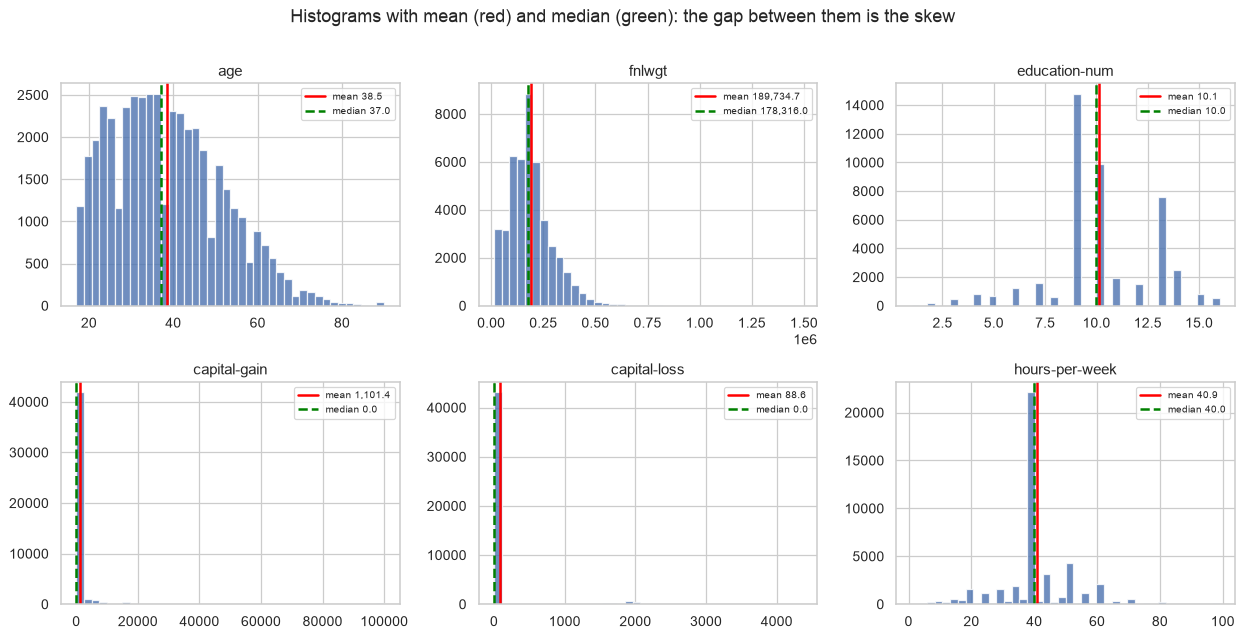

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), NUMERIC):
    ax.hist(df[col], bins=40, color="C0", alpha=.8)
    ax.axvline(df[col].mean(), color="red", lw=2, label=f"mean {df[col].mean():,.1f}")
    ax.axvline(df[col].median(), color="green", lw=2, ls="--", label=f"median {df[col].median():,.1f}")
    ax.set(title=col, xlabel=""); ax.legend(fontsize=8)
fig.suptitle("Histograms with mean (red) and median (green): the gap between them is the skew", y=1.01)
plt.show()

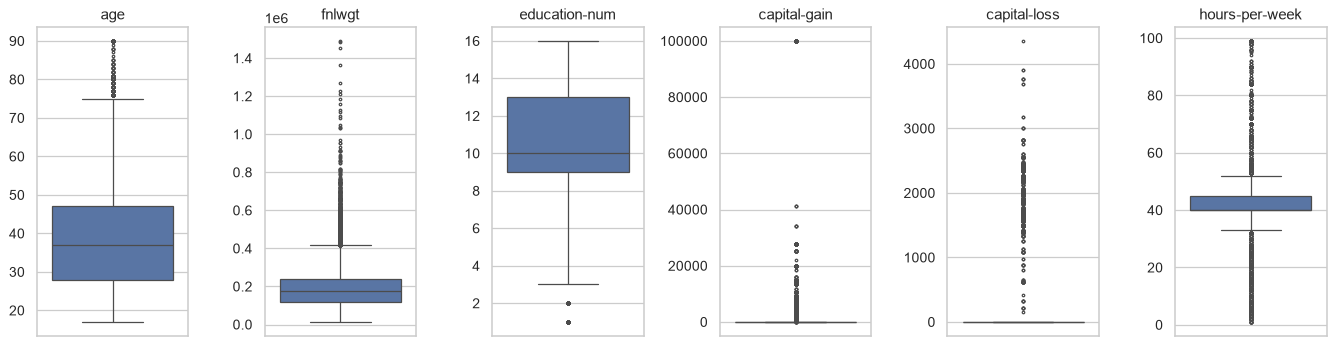

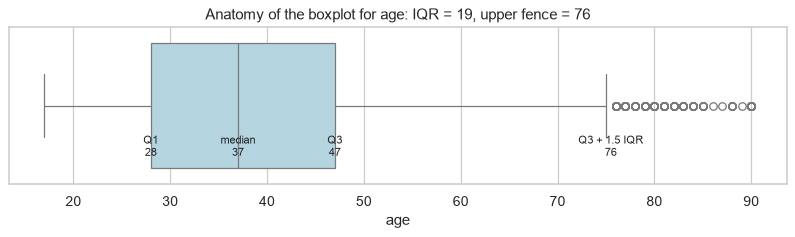

269 people (0.59%) are older than the upper fence of 76.


In [10]:
fig, axes = plt.subplots(1, 6, figsize=(15, 4))
for ax, col in zip(axes, NUMERIC):
    sns.boxplot(y=df[col], ax=ax, color="C0", fliersize=2)
    ax.set_title(col); ax.set_ylabel("")
plt.show()

# anatomy of one boxplot, annotated from the five-number summary
col = "age"
q1, med, q3 = df[col].quantile([.25, .5, .75]); iqr = q3 - q1
lo_fence, hi_fence = q1 - 1.5 * iqr, q3 + 1.5 * iqr
fig, ax = plt.subplots(figsize=(9, 2.8))
sns.boxplot(x=df[col], ax=ax, color="lightblue")
for val, lab in [(q1, "Q1"), (med, "median"), (q3, "Q3"), (hi_fence, "Q3 + 1.5 IQR")]:
    ax.annotate(f"{lab}\n{val:.0f}", (val, 0.32), ha="center", fontsize=9)
ax.set_title(f"Anatomy of the boxplot for {col}: IQR = {iqr:.0f}, upper fence = {hi_fence:.0f}")
plt.show()
n_out = ((df[col] < lo_fence) | (df[col] > hi_fence)).sum()
print(f"{n_out} people ({n_out / len(df):.2%}) are older than the upper fence of {hi_fence:.0f}.")

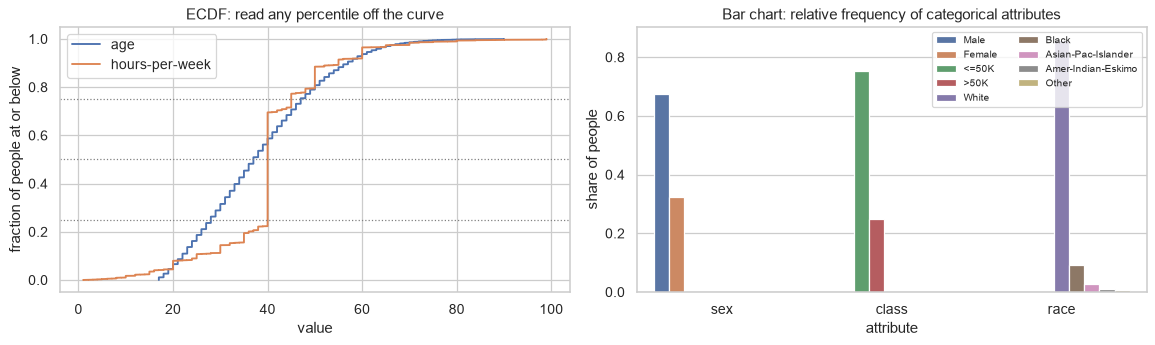

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for col, c in [("age", "C0"), ("hours-per-week", "C1")]:
    v = np.sort(df[col].to_numpy())
    axes[0].plot(v, np.arange(1, len(v) + 1) / len(v), label=col, color=c)
v = np.sort(df["age"].to_numpy()); ecdf = np.arange(1, len(v) + 1) / len(v)
for p in (.25, .5, .75):
    axes[0].axhline(p, color="grey", ls=":", lw=1)
axes[0].set(title="ECDF: read any percentile off the curve", xlabel="value", ylabel="fraction of people at or below")
axes[0].legend()

freq = pd.concat({c: df[c].value_counts(normalize=True) for c in ["sex", "class", "race"]}).rename("share").reset_index()
freq.columns = ["attribute", "value", "share"]
sns.barplot(data=freq, x="attribute", y="share", hue="value", ax=axes[1])
axes[1].set(title="Bar chart: relative frequency of categorical attributes", ylabel="share of people")
axes[1].legend(fontsize=8, ncol=2)
plt.show()

In [12]:
# How many Tukey outliers does each numeric attribute have?  (feeds Unit III)
out = {}
for col in NUMERIC:
    q1, q3 = df[col].quantile([.25, .75]); iqr = q3 - q1
    out[col] = int(((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum())
pd.DataFrame({"values beyond the 1.5xIQR fences": out, "share of rows": {k: f"{v / len(df):.1%}" for k, v in out.items()}})

,values beyond the 1.5xIQR fences,share of rows
age,269,0.6%
fnlwgt,1331,2.9%
education-num,294,0.7%
capital-gain,3790,8.4%
capital-loss,2140,4.7%
hours-per-week,11899,26.3%


**Caution on "outliers".** 26% of `hours-per-week` and 8% of `capital-gain` lie "beyond the fences", which is not 26% or 8%
errors. In `hours-per-week` most people work exactly 40 hours, so the IQR is only 5 hours and the fences are very tight; in
`capital-gain` the IQR is 0, so *every* non-zero value is beyond the fences. The 1.5xIQR rule only *flags candidates*; it
does not know about spikes or zero-inflation. Unit III handles this properly.

**Putting 2.1-2.4 together.** A complete description of an attribute is: *its type* (what operations are valid) -> *a centre*
(mean/median/mode, chosen by type and skew) -> *a spread* (std or IQR, chosen by outliers/skew) -> *a picture* (histogram +
boxplot). For skewed or zero-inflated columns report **median and IQR**; for roughly symmetric ones **mean and std**.